In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
train_ratings = pd.read_csv("../data/processed/train_ratings.csv")
test_ratings = pd.read_csv("../data/processed/test_ratings.csv")

print("Train ratings:", train_ratings.shape)
print("Test ratings:", test_ratings.shape)

Train ratings: (800167, 3)
Test ratings: (200042, 3)


In [3]:
from surprise import Dataset, Reader, SVD
from surprise.accuracy import rmse, mae

print("Surprise evaluation tools imported successfully!")

Surprise evaluation tools imported successfully!


In [4]:
reader = Reader(rating_scale=(1, 5))

train_data = Dataset.load_from_df(
    train_ratings[["userId", "movieId", "rating"]],
    reader
)

trainset = train_data.build_full_trainset()

print("Training data prepared successfully!")
print("Number of users:", trainset.n_users)
print("Number of movies:", trainset.n_items)

Training data prepared successfully!
Number of users: 6040
Number of movies: 3683


In [5]:
svd_model = SVD(
    n_factors=100,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

svd_model.fit(trainset)

print("SVD model trained successfully!")

SVD model trained successfully!


In [6]:
predictions = []

for _, row in test_ratings.iterrows():
    prediction = svd_model.predict(
        row["userId"],
        row["movieId"]
    )
    predictions.append(prediction)

print("Predictions generated:", len(predictions))

Predictions generated: 200042


In [7]:
actual_ratings = test_ratings["rating"].values
predicted_ratings = np.array([pred.est for pred in predictions])

rmse_score = np.sqrt(
    np.mean((actual_ratings - predicted_ratings) ** 2)
)

mae_score = np.mean(
    np.abs(actual_ratings - predicted_ratings)
)

print("RMSE:", rmse_score)
print("MAE:", mae_score)

RMSE: 0.8783851612324959
MAE: 0.6902116038110034


In [8]:
evaluation_results = pd.DataFrame({
    "Metric": ["RMSE", "MAE"],
    "Score": [rmse_score, mae_score]
})

evaluation_results

,Metric,Score
0,RMSE,0.878385
1,MAE,0.690212


In [9]:
evaluation_results.to_csv(
    "../data/processed/evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


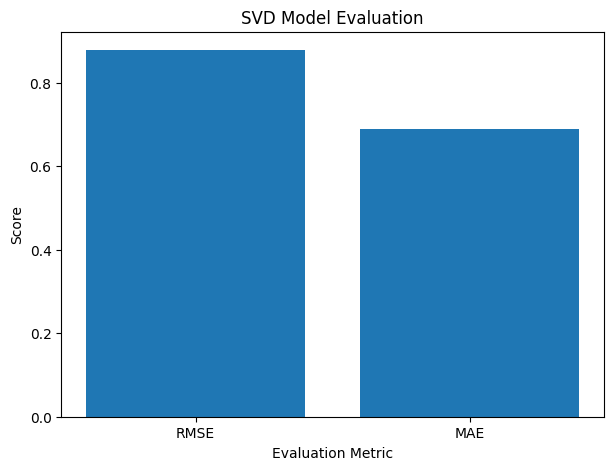

In [10]:
plt.figure(figsize=(7, 5))

plt.bar(
    evaluation_results["Metric"],
    evaluation_results["Score"]
)

plt.title("SVD Model Evaluation")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

plt.show()

In [11]:
errors = actual_ratings - predicted_ratings

print("Mean Error:", np.mean(errors))
print("Minimum Error:", np.min(errors))
print("Maximum Error:", np.max(errors))

Mean Error: 0.0018041523811897439
Minimum Error: -4.0
Maximum Error: 4.0


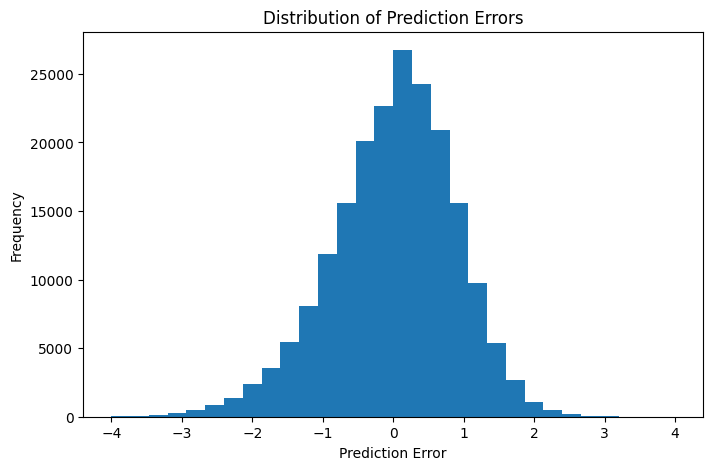

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(errors, bins=30)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

In [13]:
print("Average actual rating:", np.mean(actual_ratings))
print("Average predicted rating:", np.mean(predicted_ratings))

Average actual rating: 3.5824326891352816
Average predicted rating: 3.5806285367540918


In [14]:
diagnostic_summary = pd.DataFrame({
    "Metric": [
        "Mean Error",
        "Minimum Error",
        "Maximum Error",
        "Average Actual Rating",
        "Average Predicted Rating"
    ],
    "Value": [
        np.mean(errors),
        np.min(errors),
        np.max(errors),
        np.mean(actual_ratings),
        np.mean(predicted_ratings)
    ]
})

diagnostic_summary

,Metric,Value
0,Mean Error,0.001804
1,Minimum Error,-4.000000
2,Maximum Error,4.000000
3,Average Actual Rating,3.582433
4,Average Predicted Rating,3.580629


In [15]:
diagnostic_summary.to_csv(
    "../data/processed/diagnostic_summary.csv",
    index=False
)

print("Diagnostic summary saved successfully!")

Diagnostic summary saved successfully!


In [16]:
print("===== FINAL SVD EVALUATION =====")
print("RMSE:", round(rmse_score, 4))
print("MAE:", round(mae_score, 4))
print("Mean Error:", round(np.mean(errors), 4))
print("Average Actual Rating:", round(np.mean(actual_ratings), 4))
print("Average Predicted Rating:", round(np.mean(predicted_ratings), 4))

===== FINAL SVD EVALUATION =====
RMSE: 0.8784
MAE: 0.6902
Mean Error: 0.0018
Average Actual Rating: 3.5824
Average Predicted Rating: 3.5806
